<a href="https://colab.research.google.com/github/231230047-afk/231230047-Pengantar-ML-week-03-praktikum-3-visualisasi-data--Titanic-.ipynb/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Explorasi Data

In [29]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn import datasets

# Pengaturan visualisasi
sns.set_theme(style='whitegrid')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [30]:
# ==========================================
# 2. LOAD DATASET
# ==========================================

# Membaca dataset Titanic
df = pd.read_csv('/content/titanic.csv')

# Menampilkan 5 data pertama
print("LIMA DATA PERTAMA")
display(df.head())

# Menampilkan 5 data terakhir
print("\nLIMA DATA TERAKHIR")
display(df.tail())

print("\nDataset berhasil dimuat!")

LIMA DATA PERTAMA


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



LIMA DATA TERAKHIR


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True



Dataset berhasil dimuat!


In [31]:
# ==========================================
# 3. STRUKTUR DATASET
# ==========================================

print("UKURAN DATASET")
print("Jumlah Baris:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

print("\nNAMA FITUR")
print(df.columns.tolist())

print("\nINFORMASI DATASET")
df.info()

UKURAN DATASET
Jumlah Baris: 891
Jumlah Kolom: 15

NAMA FITUR
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    obje

In [32]:
# ==========================================
# 4. IDENTIFIKASI TIPE DATA
# ==========================================

print("TIPE DATA SETIAP FITUR")
print(df.dtypes)

# Memisahkan fitur numerik
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Memisahkan fitur kategorikal
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nFITUR NUMERIK")
print(numerical_features)

print("\nFITUR KATEGORIKAL")
print(categorical_features)

TIPE DATA SETIAP FITUR
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

FITUR NUMERIK
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

FITUR KATEGORIKAL
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


TABEL MISSING VALUES


,Jumlah Missing,Persentase (%)
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
class,0,0.00
who,0,0.00


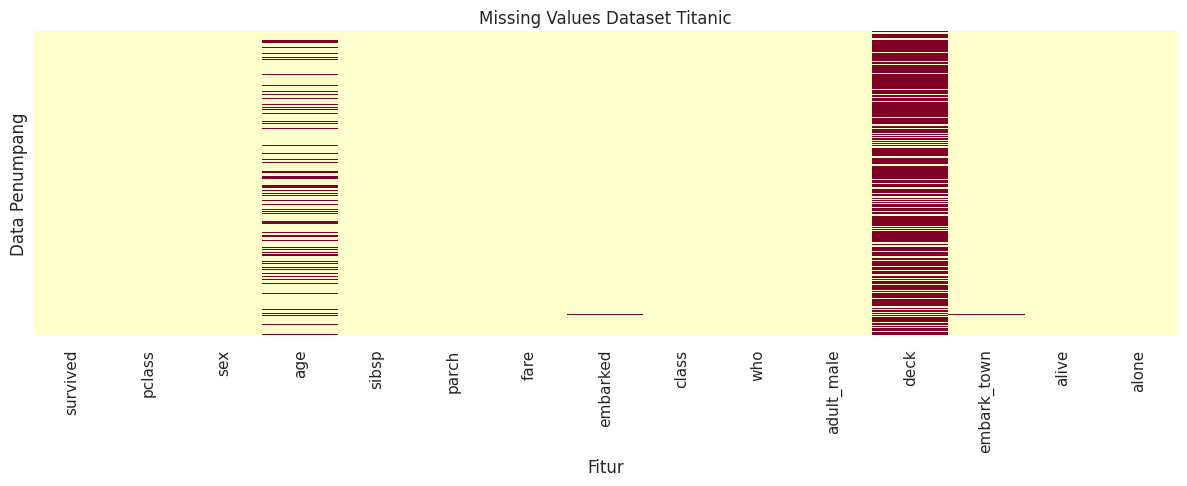

In [33]:
# ==========================================
# 5. MISSING VALUES
# ==========================================

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_table = pd.DataFrame({
    'Jumlah Missing': missing_count,
    'Persentase (%)': missing_percentage
})

print("TABEL MISSING VALUES")
display(missing_table)

# Visualisasi missing values
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='YlOrRd',
    yticklabels=False
)

plt.title('Missing Values Dataset Titanic')
plt.xlabel('Fitur')
plt.ylabel('Data Penumpang')

plt.tight_layout()
plt.show()

In [34]:
# ==========================================
# 6. STATISTIK DESKRIPTIF
# ==========================================

print("STATISTIK DESKRIPTIF NUMERIK")
display(df.describe())

print("\nSTATISTIK DESKRIPTIF KATEGORIKAL")
display(df.describe(include='object'))

STATISTIK DESKRIPTIF NUMERIK


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



STATISTIK DESKRIPTIF KATEGORIKAL


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


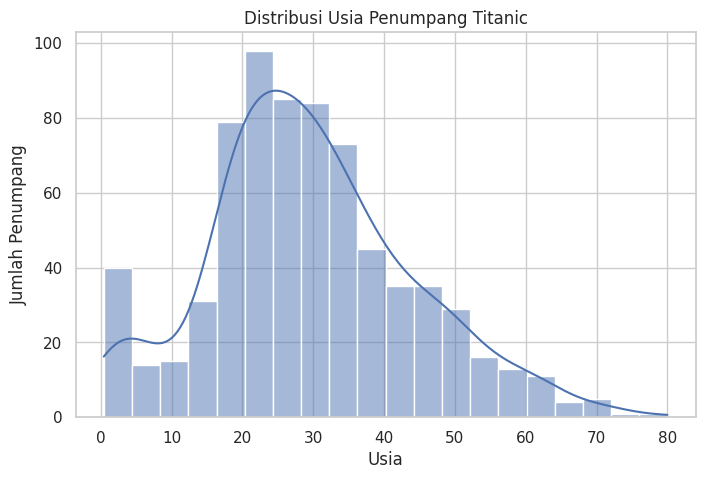

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x='age', bins=20, kde=True)

plt.title('Distribusi Usia Penumpang Titanic')
plt.xlabel('Usia')
plt.ylabel('Jumlah Penumpang')
plt.show()

In [36]:
# ==========================================
# 7. KONTEKS DATASET
# ==========================================

print("""
KONTEKS DATASET TITANIC

Dataset Titanic berisi informasi penumpang kapal Titanic.

Informasi yang terdapat dalam dataset:

1. Survived    : Status keselamatan penumpang
2. Pclass      : Kelas tiket penumpang
3. Sex         : Jenis kelamin
4. Age         : Usia penumpang
5. SibSp       : Jumlah saudara atau pasangan
6. Parch       : Jumlah orang tua atau anak
7. Fare        : Harga tiket
8. Embarked    : Pelabuhan keberangkatan
9. Deck        : Lokasi dek kapal

Tujuan analisis:

Mengetahui pola dan hubungan antara karakteristik
penumpang dengan tingkat keselamatan mereka.
""")


KONTEKS DATASET TITANIC

Dataset Titanic berisi informasi penumpang kapal Titanic.

Informasi yang terdapat dalam dataset:

1. Survived    : Status keselamatan penumpang
2. Pclass      : Kelas tiket penumpang
3. Sex         : Jenis kelamin
4. Age         : Usia penumpang
5. SibSp       : Jumlah saudara atau pasangan
6. Parch       : Jumlah orang tua atau anak
7. Fare        : Harga tiket
8. Embarked    : Pelabuhan keberangkatan
9. Deck        : Lokasi dek kapal

Tujuan analisis:

Mengetahui pola dan hubungan antara karakteristik
penumpang dengan tingkat keselamatan mereka.



2. Brainstorming Visualisasi

In [37]:
# ==========================================
# 8. TUJUAN VISUALISASI
# ==========================================

print("""
BRAINSTORMING VISUALISASI

Tujuan:
Menganalisis faktor-faktor yang berhubungan
dengan tingkat keselamatan penumpang Titanic.

Visualisasi yang akan digunakan:

1. Countplot
   Menampilkan distribusi penumpang selamat
   dan tidak selamat.

2. Barplot
   Membandingkan tingkat keselamatan
   berdasarkan jenis kelamin.

3. Barplot
   Membandingkan tingkat keselamatan
   berdasarkan kelas tiket.

4. Heatmap
   Menampilkan interaksi usia, gender,
   dan kelas penumpang.

5. Boxplot
   Membandingkan distribusi usia berdasarkan
   status keselamatan dan jenis kelamin.

6. Barplot Deck
   Menganalisis pola keselamatan berdasarkan dek.

7. Barplot Embarked
   Menganalisis pola keselamatan berdasarkan
   pelabuhan keberangkatan.
""")


BRAINSTORMING VISUALISASI

Tujuan:
Menganalisis faktor-faktor yang berhubungan
dengan tingkat keselamatan penumpang Titanic.

Visualisasi yang akan digunakan:

1. Countplot
   Menampilkan distribusi penumpang selamat
   dan tidak selamat.

2. Barplot
   Membandingkan tingkat keselamatan
   berdasarkan jenis kelamin.

3. Barplot
   Membandingkan tingkat keselamatan
   berdasarkan kelas tiket.

4. Heatmap
   Menampilkan interaksi usia, gender,
   dan kelas penumpang.

5. Boxplot
   Membandingkan distribusi usia berdasarkan
   status keselamatan dan jenis kelamin.

6. Barplot Deck
   Menganalisis pola keselamatan berdasarkan dek.

7. Barplot Embarked
   Menganalisis pola keselamatan berdasarkan
   pelabuhan keberangkatan.



In [38]:
# ==========================================
# 9. PERSIAPAN DATA VISUALISASI
# ==========================================

# Membuat salinan dataset
data = df.copy()

# Membuat label keselamatan
data['status_keselamatan'] = data['survived'].map({
    0: 'Tidak Selamat',
    1: 'Selamat'
})

# Membuat kelompok usia
data['kelompok_usia'] = pd.cut(
    data['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=[
        'Anak-anak',
        'Remaja',
        'Dewasa Muda',
        'Dewasa',
        'Lansia'
    ],
    include_lowest=True
)

# Urutan kategori
status_order = ['Tidak Selamat', 'Selamat']
gender_order = ['female', 'male']
class_order = ['First', 'Second', 'Third']

print("DATA BERHASIL DISIAPKAN")

display(data.head())

DATA BERHASIL DISIAPKAN


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,status_keselamatan,kelompok_usia
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Tidak Selamat,Dewasa Muda
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Selamat,Dewasa
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Selamat,Dewasa Muda
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Selamat,Dewasa Muda
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Tidak Selamat,Dewasa Muda


In [39]:
# ==========================================
# 10. ALASAN PEMILIHAN VISUALISASI
# ==========================================

alasan = {
    'Countplot':
    'Untuk melihat jumlah penumpang selamat dan tidak selamat.',

    'Barplot':
    'Untuk membandingkan persentase keselamatan berdasarkan kategori.',

    'Heatmap':
    'Untuk melihat pola interaksi beberapa variabel sekaligus.',

    'Boxplot':
    'Untuk melihat distribusi usia berdasarkan kategori keselamatan.',

    'Barplot Deck dan Embarked':
    'Untuk mengetahui perbedaan keselamatan berdasarkan lokasi dek dan pelabuhan.'
}

for nama, penjelasan in alasan.items():
    print(f"\n{nama}")
    print(penjelasan)


Countplot
Untuk melihat jumlah penumpang selamat dan tidak selamat.

Barplot
Untuk membandingkan persentase keselamatan berdasarkan kategori.

Heatmap
Untuk melihat pola interaksi beberapa variabel sekaligus.

Boxplot
Untuk melihat distribusi usia berdasarkan kategori keselamatan.

Barplot Deck dan Embarked
Untuk mengetahui perbedaan keselamatan berdasarkan lokasi dek dan pelabuhan.


3. Implementasi dan Analisis Visualisasi

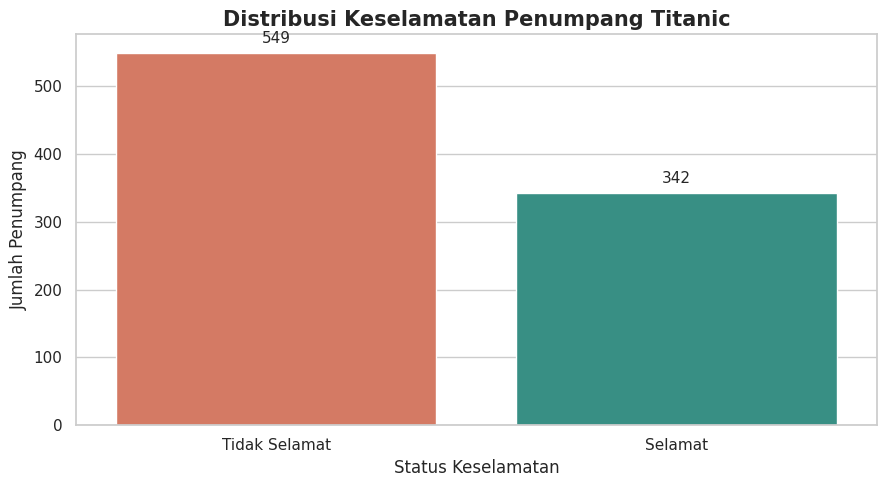

KEY INSIGHTS VISUALISASI 1
Tidak Selamat: 549
Selamat: 342
Persentase tidak selamat: 61.62%
Persentase selamat: 38.38%

KESIMPULAN:
Jumlah penumpang yang tidak selamat lebih banyak
dibandingkan penumpang yang berhasil selamat.



In [40]:
# ==========================================
# 11. VISUALISASI 1
# DISTRIBUSI KESELAMATAN PENUMPANG
# ==========================================

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=data,
    x='status_keselamatan',
    order=status_order,
    hue='status_keselamatan',
    palette=['#E76F51', '#2A9D8F'],
    legend=False
)

# Menampilkan jumlah di atas batang
for container in ax.containers:
    ax.bar_label(container, padding=5)

plt.title(
    'Distribusi Keselamatan Penumpang Titanic',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Status Keselamatan')
plt.ylabel('Jumlah Penumpang')

plt.tight_layout()
plt.show()

# ANALISIS
jumlah_tidak_selamat = (data['survived'] == 0).sum()
jumlah_selamat = (data['survived'] == 1).sum()

print("KEY INSIGHTS VISUALISASI 1")
print("Tidak Selamat:", jumlah_tidak_selamat)
print("Selamat:", jumlah_selamat)

print(f"Persentase tidak selamat: {jumlah_tidak_selamat / len(data) * 100:.2f}%")
print(f"Persentase selamat: {jumlah_selamat / len(data) * 100:.2f}%")

print("""
KESIMPULAN:
Jumlah penumpang yang tidak selamat lebih banyak
dibandingkan penumpang yang berhasil selamat.
""")

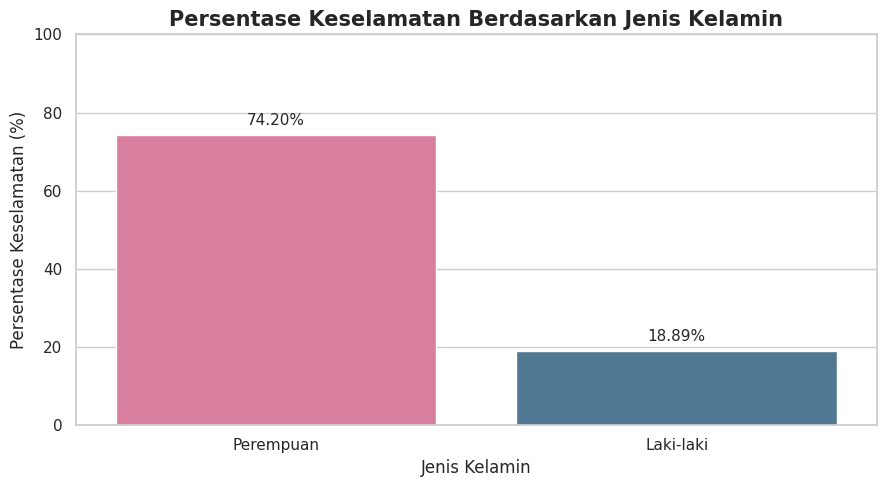

KEY INSIGHTS VISUALISASI 2
Perempuan: 74.20%
Laki-laki: 18.89%

KESIMPULAN:
Perempuan memiliki tingkat keselamatan lebih tinggi
dibandingkan laki-laki dalam dataset Titanic.



In [41]:
# ==========================================
# 12. VISUALISASI 2
# KESELAMATAN BERDASARKAN JENIS KELAMIN
# ==========================================

survival_sex = (
    data.groupby('sex')['survived'].mean() * 100
).reindex(gender_order)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_sex.index,
    y=survival_sex.values,
    hue=survival_sex.index,
    palette=['#E76F9A', '#457B9D'],
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=5
    )

plt.title(
    'Persentase Keselamatan Berdasarkan Jenis Kelamin',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Jenis Kelamin')
plt.ylabel('Persentase Keselamatan (%)')

plt.xticks([0, 1], ['Perempuan', 'Laki-laki'])
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# ANALISIS
print("KEY INSIGHTS VISUALISASI 2")

print(f"Perempuan: {survival_sex['female']:.2f}%")
print(f"Laki-laki: {survival_sex['male']:.2f}%")

print("""
KESIMPULAN:
Perempuan memiliki tingkat keselamatan lebih tinggi
dibandingkan laki-laki dalam dataset Titanic.
""")

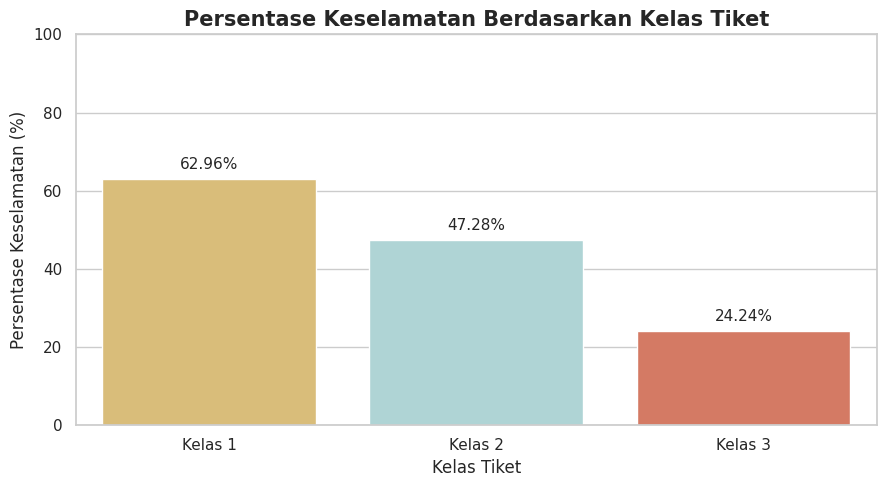

KEY INSIGHTS VISUALISASI 3
Kelas First: 62.96%
Kelas Second: 47.28%
Kelas Third: 24.24%

KESIMPULAN:
Kelas pertama memiliki tingkat keselamatan tertinggi,
sedangkan kelas ketiga memiliki tingkat keselamatan
terendah.



In [42]:
# ==========================================
# 13. VISUALISASI 3
# KESELAMATAN BERDASARKAN KELAS TIKET
# ==========================================

survival_class = (
    data.groupby('class', observed=True)['survived']
    .mean() * 100
).reindex(class_order)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_class.index,
    y=survival_class.values,
    hue=survival_class.index,
    palette=['#E9C46A', '#A8DADC', '#E76F51'],
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=5
    )

plt.title(
    'Persentase Keselamatan Berdasarkan Kelas Tiket',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Kelas Tiket')
plt.ylabel('Persentase Keselamatan (%)')

plt.xticks([0, 1, 2], ['Kelas 1', 'Kelas 2', 'Kelas 3'])
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# ANALISIS
print("KEY INSIGHTS VISUALISASI 3")

for kelas, nilai in survival_class.items():
    print(f"Kelas {kelas}: {nilai:.2f}%")

print("""
KESIMPULAN:
Kelas pertama memiliki tingkat keselamatan tertinggi,
sedangkan kelas ketiga memiliki tingkat keselamatan
terendah.
""")

TABEL PERBANDINGAN TINGKAT KESELAMATAN


,Jenis Kelamin,Kelas Tiket,Kelompok Usia,Pelabuhan
female,74.20,NaN,NaN,NaN
male,18.89,NaN,NaN,NaN
First,NaN,62.96,NaN,NaN
Second,NaN,47.28,NaN,NaN
Third,NaN,24.24,NaN,NaN
Anak-anak,NaN,NaN,57.97,NaN
Remaja,NaN,NaN,42.86,NaN
Dewasa Muda,NaN,NaN,38.27,NaN
Dewasa,NaN,NaN,40.00,NaN
Lansia,NaN,NaN,22.73,NaN



PERBEDAAN SURVIVAL RATE ANTAR KATEGORI


,Selisih Persentase (%)
Jenis Kelamin,55.31
Kelas Tiket,38.73
Kelompok Usia,35.24
Pelabuhan,21.66


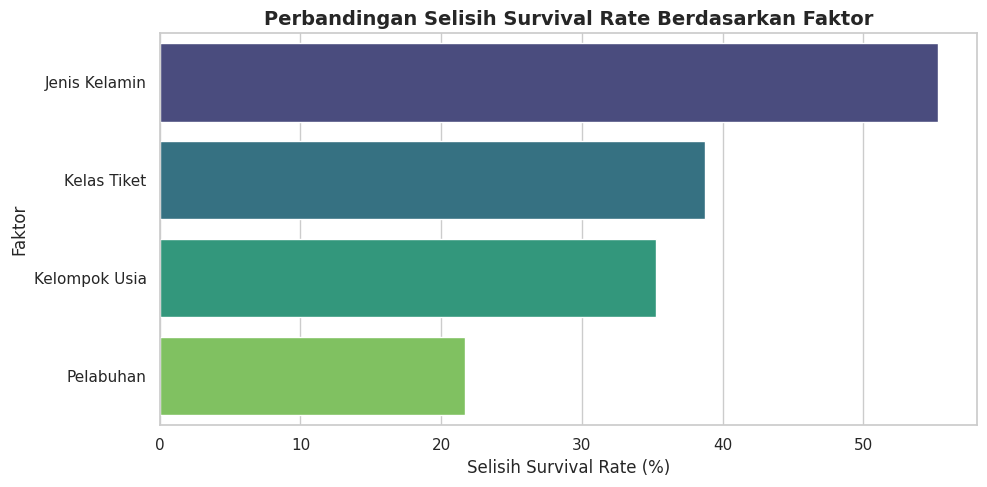


FAKTOR DENGAN PERBEDAAN SURVIVAL RATE TERBESAR:
Jenis Kelamin
Selisih: 55.31%

CATATAN:
Perbandingan ini menunjukkan faktor dengan perbedaan
survival rate terbesar antar kelompok, bukan bukti
bahwa faktor tersebut secara kausal paling memengaruhi
keselamatan penumpang.



In [43]:
# ==========================================
# 14. FAKTOR YANG BERHUBUNGAN DENGAN SURVIVAL
# ==========================================

# Menghitung survival rate berdasarkan beberapa faktor
faktor_survival = pd.concat([
    (data.groupby('sex')['survived'].mean() * 100)
        .rename('Jenis Kelamin'),

    (data.groupby('class', observed=True)['survived'].mean() * 100)
        .rename('Kelas Tiket'),

    (data.groupby('kelompok_usia', observed=True)['survived'].mean() * 100)
        .rename('Kelompok Usia'),

    (data.groupby('embarked')['survived'].mean() * 100)
        .rename('Pelabuhan')
], axis=1)

print("TABEL PERBANDINGAN TINGKAT KESELAMATAN")
display(faktor_survival.round(2))

# Menghitung rentang survival setiap faktor
rentang_faktor = pd.Series({
    'Jenis Kelamin': (
        data.groupby('sex')['survived'].mean().max()
        - data.groupby('sex')['survived'].mean().min()
    ) * 100,

    'Kelas Tiket': (
        data.groupby('class', observed=True)['survived'].mean().max()
        - data.groupby('class', observed=True)['survived'].mean().min()
    ) * 100,

    'Kelompok Usia': (
        data.groupby('kelompok_usia', observed=True)['survived'].mean().max()
        - data.groupby('kelompok_usia', observed=True)['survived'].mean().min()
    ) * 100,

    'Pelabuhan': (
        data.groupby('embarked')['survived'].mean().max()
        - data.groupby('embarked')['survived'].mean().min()
    ) * 100
})

rentang_faktor = rentang_faktor.sort_values(ascending=False)

print("\nPERBEDAAN SURVIVAL RATE ANTAR KATEGORI")
display(rentang_faktor.round(2).to_frame('Selisih Persentase (%)'))

# Visualisasi perbandingan
plt.figure(figsize=(10, 5))

sns.barplot(
    x=rentang_faktor.values,
    y=rentang_faktor.index,
    hue=rentang_faktor.index,
    palette='viridis',
    legend=False
)

plt.title(
    'Perbandingan Selisih Survival Rate Berdasarkan Faktor',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Selisih Survival Rate (%)')
plt.ylabel('Faktor')

plt.tight_layout()
plt.show()

print("\nFAKTOR DENGAN PERBEDAAN SURVIVAL RATE TERBESAR:")
print(rentang_faktor.index[0])
print(f"Selisih: {rentang_faktor.iloc[0]:.2f}%")

print("""
CATATAN:
Perbandingan ini menunjukkan faktor dengan perbedaan
survival rate terbesar antar kelompok, bukan bukti
bahwa faktor tersebut secara kausal paling memengaruhi
keselamatan penumpang.
""")

In [44]:
# ==========================================
# 15. ANALISIS HUBUNGAN KELAS DAN SURVIVAL
# ==========================================

tabel_kelas = data.groupby(
    'class',
    observed=True
)['survived'].agg(
    Jumlah_Penumpang='count',
    Jumlah_Selamat='sum',
    Rata_Rata_Survival='mean'
)

tabel_kelas['Survival_Persen'] = (
    tabel_kelas['Rata_Rata_Survival'] * 100
)

print("ANALISIS KELAS PENUMPANG")
display(tabel_kelas.round(2))

print("""
KESIMPULAN:

Terdapat perbedaan tingkat keselamatan berdasarkan
kelas tiket penumpang.

Penumpang kelas pertama memiliki tingkat survival
lebih tinggi dibandingkan kelas kedua dan ketiga.
""")

ANALISIS KELAS PENUMPANG


,Jumlah_Penumpang,Jumlah_Selamat,Rata_Rata_Survival,Survival_Persen
class,,,,
First,216,136,0.63,62.96
Second,184,87,0.47,47.28
Third,491,119,0.24,24.24



KESIMPULAN:

Terdapat perbedaan tingkat keselamatan berdasarkan
kelas tiket penumpang.

Penumpang kelas pertama memiliki tingkat survival
lebih tinggi dibandingkan kelas kedua dan ketiga.



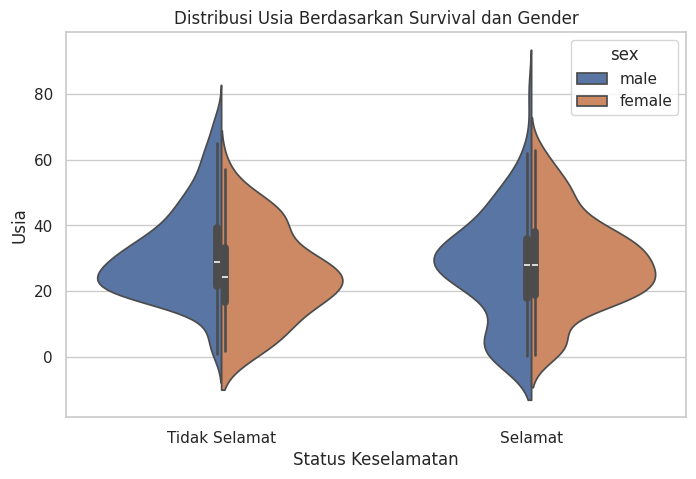

In [45]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=data,
    x='status_keselamatan',
    y='age',
    hue='sex',
    split=True
)

plt.title('Distribusi Usia Berdasarkan Survival dan Gender')
plt.xlabel('Status Keselamatan')
plt.ylabel('Usia')
plt.show()

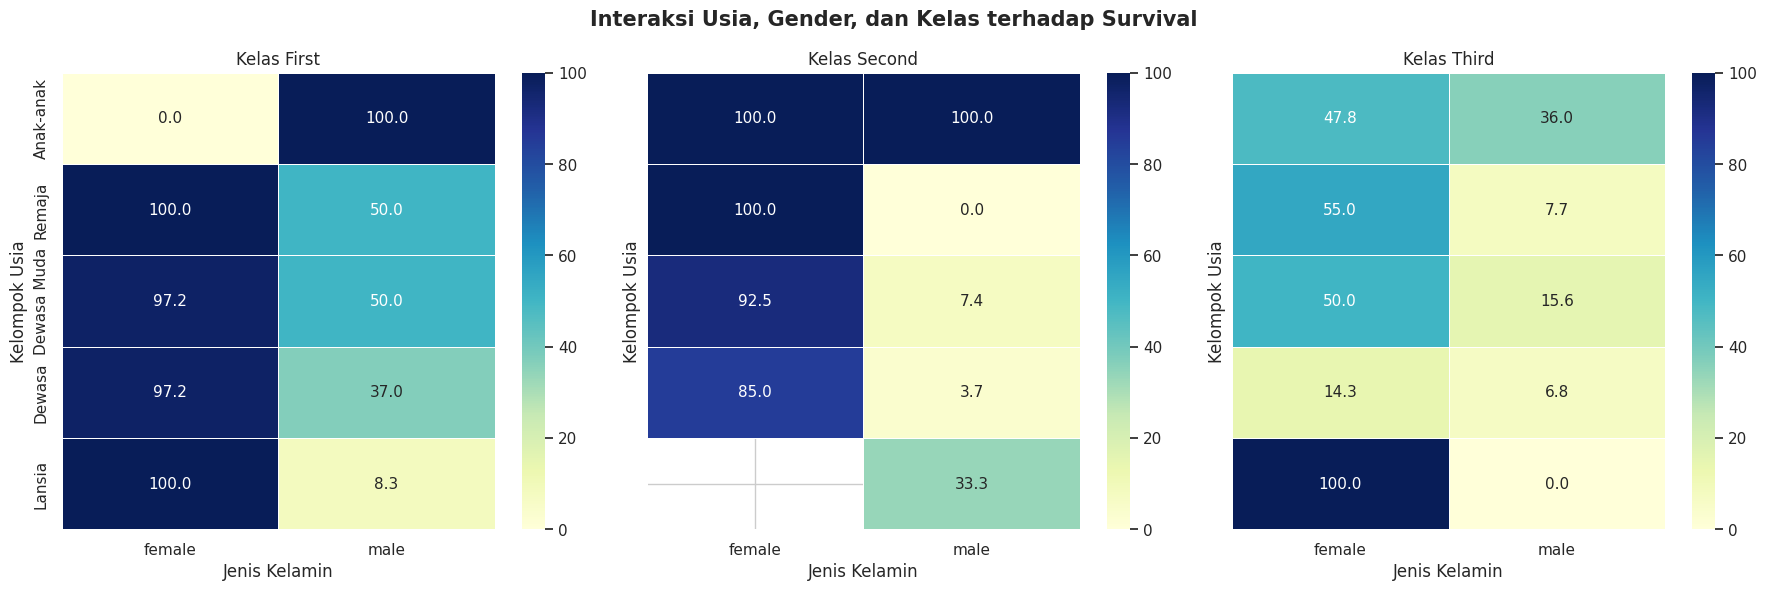

TABEL INTERAKSI USIA DAN GENDER


sex,female,male
kelompok_usia,,
Anak-anak,59.38,56.76
Remaja,75.00,8.82
Dewasa Muda,78.33,18.07
Dewasa,77.14,19.20
Lansia,100.00,10.53



KESIMPULAN:

Heatmap digunakan untuk melihat perbedaan survival
berdasarkan kombinasi kelompok usia, jenis kelamin,
dan kelas tiket.

Warna yang semakin tinggi menunjukkan persentase
keselamatan yang lebih tinggi.

Perlu diperhatikan bahwa beberapa kelompok mungkin
memiliki jumlah penumpang sedikit, sehingga hasilnya
perlu diinterpretasikan secara hati-hati.



In [46]:
# ==========================================
# 16. INTERAKSI USIA, GENDER, DAN KELAS
# ==========================================

# Menghitung survival rate berdasarkan
# kelompok usia, jenis kelamin, dan kelas

interaksi = data.pivot_table(
    index='kelompok_usia',
    columns='sex',
    values='survived',
    aggfunc='mean',
    observed=False
) * 100

# Membuat 3 heatmap berdasarkan kelas
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharey=True
)

for ax, kelas in zip(axes, class_order):

    subset = data[data['class'] == kelas]

    pivot = subset.pivot_table(
        index='kelompok_usia',
        columns='sex',
        values='survived',
        aggfunc='mean',
        observed=False
    ) * 100

    sns.heatmap(
        pivot,
        annot=True,
        fmt='.1f',
        cmap='YlGnBu',
        vmin=0,
        vmax=100,
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(f'Kelas {kelas}')
    ax.set_xlabel('Jenis Kelamin')
    ax.set_ylabel('Kelompok Usia')

plt.suptitle(
    'Interaksi Usia, Gender, dan Kelas terhadap Survival',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

print("TABEL INTERAKSI USIA DAN GENDER")
display(interaksi.round(2))

print("""
KESIMPULAN:

Heatmap digunakan untuk melihat perbedaan survival
berdasarkan kombinasi kelompok usia, jenis kelamin,
dan kelas tiket.

Warna yang semakin tinggi menunjukkan persentase
keselamatan yang lebih tinggi.

Perlu diperhatikan bahwa beberapa kelompok mungkin
memiliki jumlah penumpang sedikit, sehingga hasilnya
perlu diinterpretasikan secara hati-hati.
""")

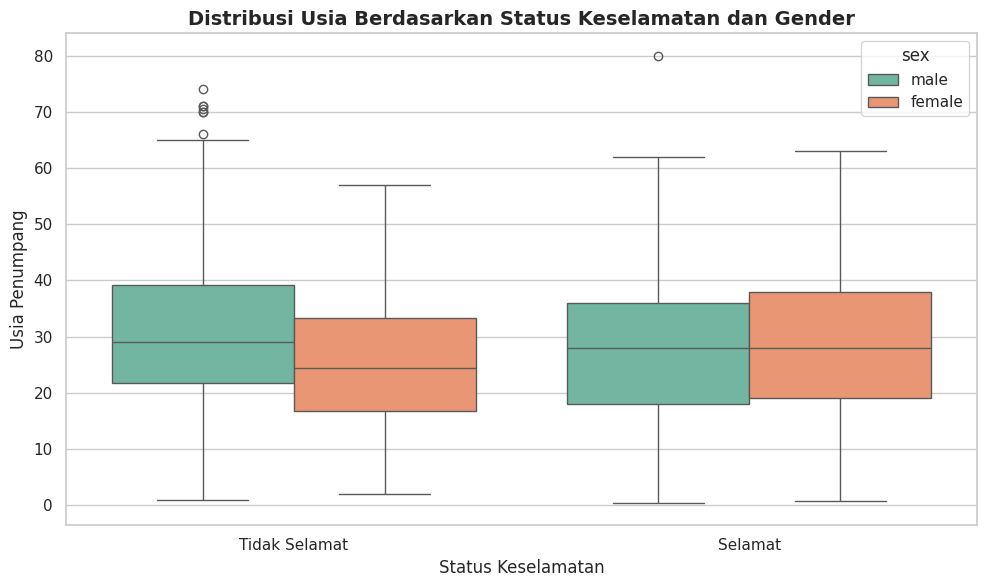


ANALISIS:

Boxplot digunakan untuk menampilkan distribusi usia
berdasarkan status keselamatan dan jenis kelamin.

Grafik ini memperlihatkan:
1. Median usia penumpang.
2. Sebaran atau rentang usia.
3. Perbedaan distribusi usia antar kelompok.
4. Kemungkinan adanya data pencilan (outlier).

KESIMPULAN:

Boxplot efektif untuk menganalisis data campuran
karena dapat membandingkan fitur numerik berdasarkan
kategori tertentu.



In [47]:
# ==========================================
# 17. VISUALISASI DATA CAMPURAN
# ==========================================

plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=data,
    x='status_keselamatan',
    y='age',
    hue='sex',
    order=status_order,
    palette='Set2'
)

plt.title(
    'Distribusi Usia Berdasarkan Status Keselamatan dan Gender',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Status Keselamatan')
plt.ylabel('Usia Penumpang')

plt.tight_layout()
plt.show()

print("""
ANALISIS:

Boxplot digunakan untuk menampilkan distribusi usia
berdasarkan status keselamatan dan jenis kelamin.

Grafik ini memperlihatkan:
1. Median usia penumpang.
2. Sebaran atau rentang usia.
3. Perbedaan distribusi usia antar kelompok.
4. Kemungkinan adanya data pencilan (outlier).

KESIMPULAN:

Boxplot efektif untuk menganalisis data campuran
karena dapat membandingkan fitur numerik berdasarkan
kategori tertentu.
""")

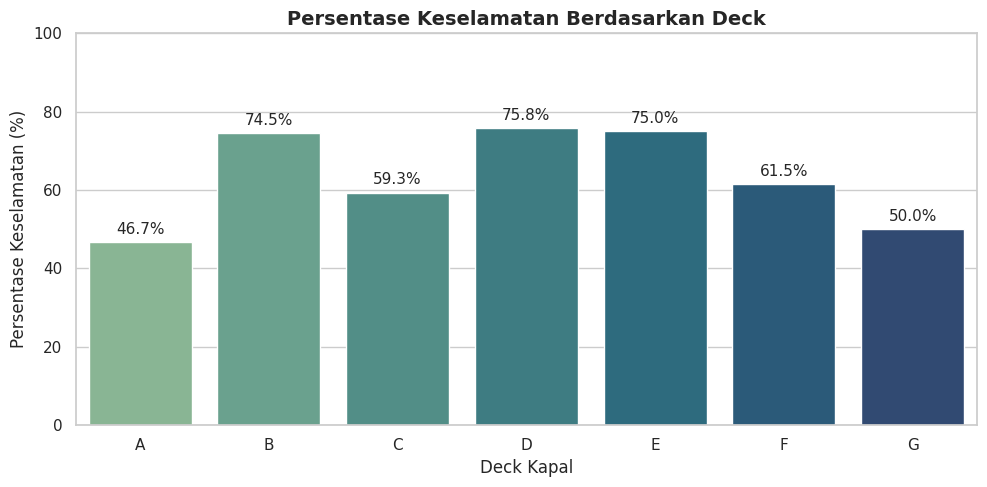

JUMLAH DATA DECK
Data deck tersedia: 203
Data deck kosong: 688

SURVIVAL RATE BERDASARKAN DECK


,Survival (%)
deck,
A,46.67
B,74.47
C,59.32
D,75.76
E,75.00
F,61.54
G,50.00



CATATAN:
Analisis deck hanya menggunakan penumpang yang
memiliki informasi deck.

Sebagian besar data deck kosong, sehingga hasil
analisis ini tidak mewakili seluruh penumpang.



In [48]:
# ==========================================
# 18. POLA SURVIVAL BERDASARKAN DECK
# ==========================================

# Mengambil data yang memiliki informasi deck
data_deck = data.dropna(subset=['deck']).copy()

# Menghitung persentase keselamatan berdasarkan deck
survival_deck = (
    data_deck.groupby('deck')['survived']
    .mean() * 100
).sort_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=survival_deck.index,
    y=survival_deck.values,
    hue=survival_deck.index,
    palette='crest',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4
    )

plt.title(
    'Persentase Keselamatan Berdasarkan Deck',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Deck Kapal')
plt.ylabel('Persentase Keselamatan (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

print("JUMLAH DATA DECK")
print("Data deck tersedia:", len(data_deck))
print("Data deck kosong:", data['deck'].isnull().sum())

print("\nSURVIVAL RATE BERDASARKAN DECK")
display(survival_deck.round(2).to_frame('Survival (%)'))

print("""
CATATAN:
Analisis deck hanya menggunakan penumpang yang
memiliki informasi deck.

Sebagian besar data deck kosong, sehingga hasil
analisis ini tidak mewakili seluruh penumpang.
""")

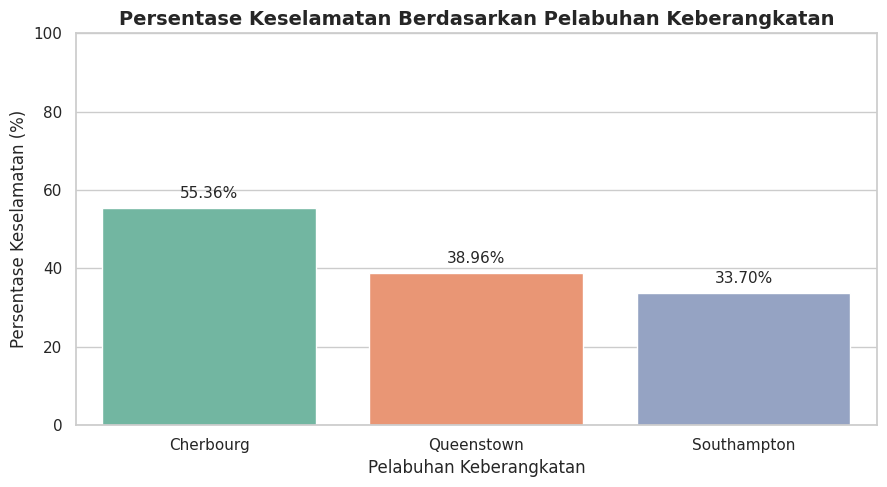

SURVIVAL RATE BERDASARKAN PELABUHAN


,Survival (%)
embarked,
Cherbourg,55.36
Queenstown,38.96
Southampton,33.70



KESIMPULAN:

Visualisasi menunjukkan perbedaan persentase
keselamatan berdasarkan pelabuhan keberangkatan.

Perbedaan ini merupakan pola dalam dataset dan
tidak membuktikan bahwa pelabuhan keberangkatan
menyebabkan penumpang selamat atau tidak selamat.



In [49]:
# ==========================================
# 19. POLA SURVIVAL BERDASARKAN EMBARKATION
# ==========================================

# Menghapus data embarked yang kosong
data_embarked = data.dropna(subset=['embarked']).copy()

# Menghitung survival rate
survival_embarked = (
    data_embarked.groupby('embarked')['survived']
    .mean() * 100
)

# Mengubah kode pelabuhan menjadi nama
nama_pelabuhan = {
    'S': 'Southampton',
    'C': 'Cherbourg',
    'Q': 'Queenstown'
}

survival_embarked.index = (
    survival_embarked.index.map(nama_pelabuhan)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=survival_embarked.index,
    y=survival_embarked.values,
    hue=survival_embarked.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=5
    )

plt.title(
    'Persentase Keselamatan Berdasarkan Pelabuhan Keberangkatan',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Pelabuhan Keberangkatan')
plt.ylabel('Persentase Keselamatan (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

print("SURVIVAL RATE BERDASARKAN PELABUHAN")
display(survival_embarked.round(2).to_frame('Survival (%)'))

print("""
KESIMPULAN:

Visualisasi menunjukkan perbedaan persentase
keselamatan berdasarkan pelabuhan keberangkatan.

Perbedaan ini merupakan pola dalam dataset dan
tidak membuktikan bahwa pelabuhan keberangkatan
menyebabkan penumpang selamat atau tidak selamat.
""")

In [50]:
# ==========================================
# 20. BUSINESS / RESEARCH IMPLICATIONS
# ==========================================

print("""
BUSINESS / RESEARCH IMPLICATIONS

Berdasarkan hasil analisis dataset Titanic:

1. Distribusi Keselamatan
   Jumlah penumpang tidak selamat lebih banyak
   dibandingkan penumpang yang selamat.

2. Jenis Kelamin
   Perempuan memiliki tingkat keselamatan lebih
   tinggi dibandingkan laki-laki.

3. Kelas Penumpang
   Penumpang kelas pertama memiliki tingkat
   keselamatan lebih tinggi dibandingkan kelas
   kedua dan ketiga.

4. Usia dan Gender
   Kombinasi usia dan jenis kelamin memperlihatkan
   pola keselamatan yang berbeda pada setiap kelas.

5. Deck dan Embarkation Port
   Terdapat perbedaan tingkat keselamatan berdasarkan
   dek kapal dan pelabuhan keberangkatan.

IMPLIKASI PENELITIAN:

Hasil visualisasi dapat digunakan untuk memahami
pola keselamatan penumpang berdasarkan karakteristik
demografis dan perjalanan.

Hasil ini juga dapat menjadi dasar untuk penelitian
lebih lanjut menggunakan metode klasifikasi
atau prediksi Machine Learning.
""")


BUSINESS / RESEARCH IMPLICATIONS

Berdasarkan hasil analisis dataset Titanic:

1. Distribusi Keselamatan
   Jumlah penumpang tidak selamat lebih banyak
   dibandingkan penumpang yang selamat.

2. Jenis Kelamin
   Perempuan memiliki tingkat keselamatan lebih
   tinggi dibandingkan laki-laki.

3. Kelas Penumpang
   Penumpang kelas pertama memiliki tingkat
   keselamatan lebih tinggi dibandingkan kelas
   kedua dan ketiga.

4. Usia dan Gender
   Kombinasi usia dan jenis kelamin memperlihatkan
   pola keselamatan yang berbeda pada setiap kelas.

5. Deck dan Embarkation Port
   Terdapat perbedaan tingkat keselamatan berdasarkan
   dek kapal dan pelabuhan keberangkatan.

IMPLIKASI PENELITIAN:

Hasil visualisasi dapat digunakan untuk memahami
pola keselamatan penumpang berdasarkan karakteristik
demografis dan perjalanan.

Hasil ini juga dapat menjadi dasar untuk penelitian
lebih lanjut menggunakan metode klasifikasi
atau prediksi Machine Learning.



In [51]:
# ==========================================
# 21. RECOMMENDATIONS
# ==========================================

recommendations = [
    "Menganalisis tingkat keselamatan berdasarkan kelompok usia.",
    "Menganalisis hubungan jenis kelamin dengan kelas tiket.",
    "Menganalisis hubungan jumlah anggota keluarga dengan survival.",
    "Menganalisis pola keselamatan berdasarkan deck dan pelabuhan.",
    "Menangani missing values agar analisis lebih lengkap.",
    "Menggunakan algoritma Machine Learning untuk prediksi survival."
]

print("RECOMMENDATIONS\n")

for i, item in enumerate(recommendations, start=1):
    print(f"{i}. {item}")

RECOMMENDATIONS

1. Menganalisis tingkat keselamatan berdasarkan kelompok usia.
2. Menganalisis hubungan jenis kelamin dengan kelas tiket.
3. Menganalisis hubungan jumlah anggota keluarga dengan survival.
4. Menganalisis pola keselamatan berdasarkan deck dan pelabuhan.
5. Menangani missing values agar analisis lebih lengkap.
6. Menggunakan algoritma Machine Learning untuk prediksi survival.


In [52]:
# ==========================================
# 22. DOKUMENTASI FINDINGS DAN PATTERNS
# ==========================================

findings = pd.DataFrame({
    'No': [1, 2, 3, 4, 5],

    'Analisis': [
        'Distribusi Keselamatan',
        'Jenis Kelamin',
        'Kelas Tiket',
        'Usia dan Gender',
        'Deck dan Embarkation'
    ],

    'Temuan': [
        f'{jumlah_selamat} penumpang selamat dan '
        f'{jumlah_tidak_selamat} tidak selamat.',

        f'Perempuan {survival_sex["female"]:.2f}% '
        f'dan laki-laki {survival_sex["male"]:.2f}%.',

        f'Kelas pertama {survival_class["First"]:.2f}%, '
        f'kelas kedua {survival_class["Second"]:.2f}%, '
        f'kelas ketiga {survival_class["Third"]:.2f}%.',

        'Pola keselamatan berbeda berdasarkan '
        'kelompok usia, gender, dan kelas.',

        'Terdapat perbedaan survival rate berdasarkan '
        'deck dan pelabuhan keberangkatan.'
    ]
})

print("TABEL DOKUMENTASI HASIL ANALISIS")

display(findings)

# Menyimpan hasil analisis
findings.to_csv(
    'hasil_analisis_titanic.csv',
    index=False
)

print("Dokumentasi berhasil disimpan!")

TABEL DOKUMENTASI HASIL ANALISIS


,No,Analisis,Temuan
0,1,Distribusi Keselamatan,342 penumpang selamat dan 549 tidak selamat.
1,2,Jenis Kelamin,Perempuan 74.20% dan laki-laki 18.89%.
2,3,Kelas Tiket,"Kelas pertama 62.96%, kelas kedua 47.28%, kela..."
3,4,Usia dan Gender,Pola keselamatan berbeda berdasarkan kelompok ...
4,5,Deck dan Embarkation,Terdapat perbedaan survival rate berdasarkan d...


Dokumentasi berhasil disimpan!


In [53]:
# ==========================================
# 23. KESIMPULAN AKHIR
# ==========================================

print("=" * 60)
print("KESIMPULAN ANALISIS DATASET TITANIC")
print("=" * 60)

print(f"""
1. Dataset memiliki {df.shape[0]} baris data
   dan {df.shape[1]} fitur.

2. Jumlah penumpang selamat:
   {jumlah_selamat} orang ({jumlah_selamat / len(data) * 100:.2f}%).

3. Jumlah penumpang tidak selamat:
   {jumlah_tidak_selamat} orang
   ({jumlah_tidak_selamat / len(data) * 100:.2f}%).

4. Tingkat keselamatan perempuan:
   {survival_sex['female']:.2f}%.

5. Tingkat keselamatan laki-laki:
   {survival_sex['male']:.2f}%.

6. Tingkat keselamatan kelas pertama:
   {survival_class['First']:.2f}%.

7. Tingkat keselamatan kelas kedua:
   {survival_class['Second']:.2f}%.

8. Tingkat keselamatan kelas ketiga:
   {survival_class['Third']:.2f}%.

9. Analisis lanjutan menunjukkan adanya pola
   keselamatan berdasarkan usia, gender, kelas,
   deck, dan pelabuhan keberangkatan.

KESIMPULAN:

Berdasarkan hasil eksplorasi dan visualisasi,
terdapat perbedaan tingkat keselamatan penumpang
berdasarkan beberapa karakteristik.

Jenis kelamin dan kelas tiket menunjukkan
perbedaan survival rate yang cukup besar.

Visualisasi membantu memahami pola dan hubungan
antarvariabel serta memberikan dasar untuk
analisis lebih lanjut.
""")

print("=" * 60)
print("SELURUH ANALISIS SELESAI")
print("=" * 60)

KESIMPULAN ANALISIS DATASET TITANIC

1. Dataset memiliki 891 baris data
   dan 15 fitur.

2. Jumlah penumpang selamat:
   342 orang (38.38%).

3. Jumlah penumpang tidak selamat:
   549 orang
   (61.62%).

4. Tingkat keselamatan perempuan:
   74.20%.

5. Tingkat keselamatan laki-laki:
   18.89%.

6. Tingkat keselamatan kelas pertama:
   62.96%.

7. Tingkat keselamatan kelas kedua:
   47.28%.

8. Tingkat keselamatan kelas ketiga:
   24.24%.

9. Analisis lanjutan menunjukkan adanya pola
   keselamatan berdasarkan usia, gender, kelas,
   deck, dan pelabuhan keberangkatan.

KESIMPULAN:

Berdasarkan hasil eksplorasi dan visualisasi,
terdapat perbedaan tingkat keselamatan penumpang
berdasarkan beberapa karakteristik.

Jenis kelamin dan kelas tiket menunjukkan
perbedaan survival rate yang cukup besar.

Visualisasi membantu memahami pola dan hubungan
antarvariabel serta memberikan dasar untuk
analisis lebih lanjut.

SELURUH ANALISIS SELESAI
